### TEL354 - Minería de Datos
# PAUTA — Taller 2: Regresión y Clasificación para Eficiencia Energética de Edificios

> ⚠️ **Documento de uso exclusivo del profesor y ayudantes. No distribuir a los estudiantes.**

**Nombre:** *(Pauta)*

---
### Notas generales para la corrección
- Los resultados numéricos pueden variar ligeramente si el estudiante usa una versión diferente de scikit-learn, pero los rangos y tendencias deben ser coherentes.
- En la elección de k óptimo, K óptimo para modelos, y parámetros de regularización: aceptar cualquier valor bien justificado con métricas.
- Las preguntas de análisis tienen respuestas esperadas indicadas, pero se valorará el razonamiento crítico y la conexión con el dominio.

## Preparación del Entorno

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      GridSearchCV, cross_val_score)
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, roc_curve, auc, classification_report,
                              mean_absolute_error, mean_squared_error, r2_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor

---
## PARTE 1: CARGA Y EXPLORACIÓN AVANZADA DE DATOS

### 1.1 Exploración Básica

In [2]:
df = pd.read_csv('energy_efficiency.csv')
print(f"Dimensiones: {df.shape}")
print(f"\nTipos de datos:\n{df.dtypes}")
df.head(10)

Dimensiones: (768, 11)

Tipos de datos:
CompacidadRelativa        float64
AreaSuperficial           float64
AreaMuros                 float64
AreaTecho                 float64
AlturaTotal               float64
Orientacion                 int64
AreaAcristalamiento       float64
DistribAcristalamiento      int64
CargaCalefaccion          float64
CargaRefrigeracion        float64
ClaseEnergetica            object
dtype: object


,CompacidadRelativa,AreaSuperficial,AreaMuros,AreaTecho,AlturaTotal,Orientacion,AreaAcristalamiento,DistribAcristalamiento,CargaCalefaccion,CargaRefrigeracion,ClaseEnergetica
0,0.74,686.0,294.0,185.2,7.0,3,0.40,1,27.68,32.69,C
1,0.66,759.5,343.0,205.1,7.0,2,0.00,0,26.17,30.03,B
2,0.86,588.0,343.0,158.8,7.0,3,0.10,0,27.19,31.28,C
3,0.76,661.5,318.5,178.6,3.5,2,0.40,3,7.15,17.13,A
4,0.71,710.5,318.5,191.8,7.0,5,0.25,0,27.37,32.52,C
5,0.90,563.5,294.0,152.1,7.0,3,0.25,3,26.86,32.73,B
6,0.62,808.5,318.5,218.3,7.0,2,0.10,5,27.60,29.10,C
7,0.82,612.5,318.5,165.4,7.0,3,0.25,3,28.90,31.32,C
8,0.86,588.0,343.0,158.8,3.5,4,0.25,3,8.86,11.00,B
9,0.86,588.0,318.5,158.8,7.0,5,0.25,2,25.75,33.98,B


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   CompacidadRelativa      768 non-null    float64
 1   AreaSuperficial         768 non-null    float64
 2   AreaMuros               768 non-null    float64
 3   AreaTecho               768 non-null    float64
 4   AlturaTotal             768 non-null    float64
 5   Orientacion             768 non-null    int64  
 6   AreaAcristalamiento     768 non-null    float64
 7   DistribAcristalamiento  768 non-null    int64  
 8   CargaCalefaccion        768 non-null    float64
 9   CargaRefrigeracion      768 non-null    float64
 10  ClaseEnergetica         768 non-null    object 
dtypes: float64(8), int64(2), object(1)
memory usage: 66.1+ KB


In [4]:
desc = df.describe()
print(desc.round(2))

       CompacidadRelativa  AreaSuperficial  AreaMuros  AreaTecho  AlturaTotal  \
count              768.00           768.00     768.00     768.00       768.00   
mean                 0.77           669.41     301.37     180.75         5.36   
std                  0.11            88.40      35.99      23.88         1.75   
min                  0.62           514.50     245.00     138.90         3.50   
25%                  0.69           588.00     294.00     158.80         3.50   
50%                  0.76           661.50     318.50     178.60         7.00   
75%                  0.86           735.00     343.00     198.50         7.00   
max                  0.98           808.50     343.00     218.30         7.00   

       Orientacion  AreaAcristalamiento  DistribAcristalamiento  \
count       768.00               768.00                  768.00   
mean          3.51                 0.23                    2.34   
std           1.10                 0.13                    1.77   
mi

**📝 Comentario esperado (Pauta):**

El dataset tiene 768 registros y 11 columnas. Las variables numéricas muestran rangos coherentes:
- `CompacidadRelativa`: 0.62–0.98 (sin outliers).
- `AlturaTotal`: solo dos valores (3.5 y 7.0), lo que indica variable discreta binaria.
- `CargaCalefaccion` y `CargaRefrigeracion`: medias en torno a 18 y 23 kWh/m² respectivamente, con std ~10 — dispersión moderada.
- `Orientacion` y `DistribAcristalamiento` son numéricas discretas que representan categorías codificadas.
- `ClaseEnergetica` es la única variable de tipo cadena (string).

### 1.2 Análisis de Valores Faltantes

In [5]:
nulos = df.isnull().sum()
print("Valores nulos por columna:")
print(nulos)
print(f"\nTotal nulos: {nulos.sum()}")

Valores nulos por columna:
CompacidadRelativa        0
AreaSuperficial           0
AreaMuros                 0
AreaTecho                 0
AlturaTotal               0
Orientacion               0
AreaAcristalamiento       0
DistribAcristalamiento    0
CargaCalefaccion          0
CargaRefrigeracion        0
ClaseEnergetica           0
dtype: int64

Total nulos: 0


**📝 Pauta:** El dataset no contiene valores nulos. El estudiante debe reportarlo explícitamente y concluir que no se requiere imputación.

**Estrategia documentada:** No se requiere tratamiento de valores faltantes. Si se encontraran en una versión alternativa del dataset, se recomendaría imputación por mediana para variables numéricas continuas e imputación por moda para variables discretas.

### 1.3 Balance de Clases

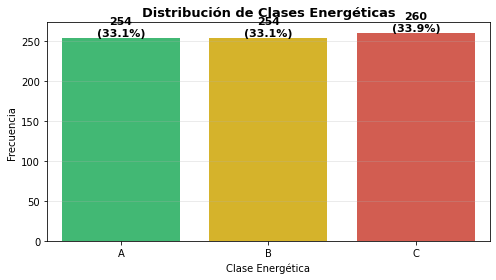


Distribución:
  Clase A: 254 (33.1%)
  Clase B: 254 (33.1%)
  Clase C: 260 (33.9%)


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
order = ['A', 'B', 'C']
counts = df['ClaseEnergetica'].value_counts()[order]
colors = ['#2ecc71', '#f1c40f', '#e74c3c']
sns.countplot(x='ClaseEnergetica', data=df, order=order, palette=colors, ax=ax)
for i, (cls, cnt) in enumerate(counts.items()):
    ax.text(i, cnt + 2, f'{cnt}\n({cnt/len(df)*100:.1f}%)', ha='center', fontsize=11, fontweight='bold')
ax.set_title('Distribución de Clases Energéticas', fontsize=13, fontweight='bold')
ax.set_xlabel('Clase Energética'); ax.set_ylabel('Frecuencia'); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()
print("\nDistribución:")
for cls in order:
    n = counts[cls]
    print(f"  Clase {cls}: {n} ({n/768*100:.1f}%)")

**📝 Pauta:** Las tres clases están **casi perfectamente balanceadas** (~33% cada una), lo que es consecuencia de la definición por terciles. Esto implica:
- No es necesario aplicar técnicas de rebalanceo (SMOTE, class_weight, etc.).
- La métrica accuracy es válida y representativa.
- Se puede usar F1-macro como métrica principal sin preocupación de sesgo hacia clases mayoritarias.

**Nota docente:** Aceptar análisis que mencione el balanceo y concluya que no requiere tratamiento adicional.

### 1.4 Análisis de Distribuciones

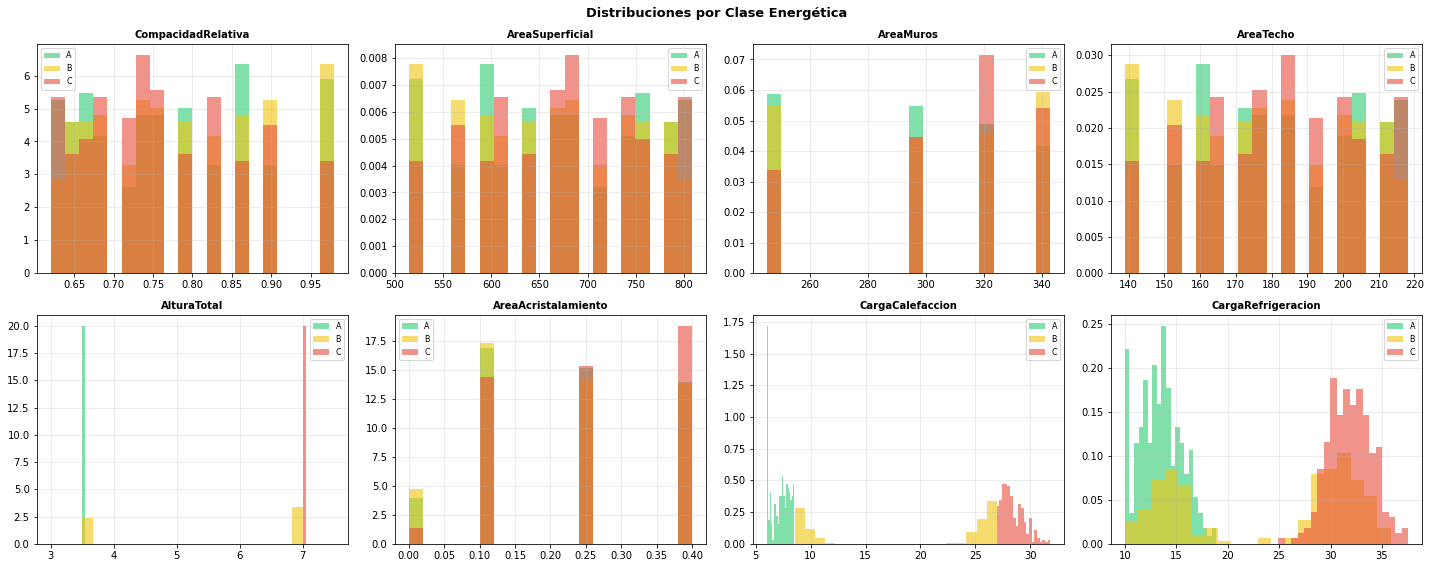

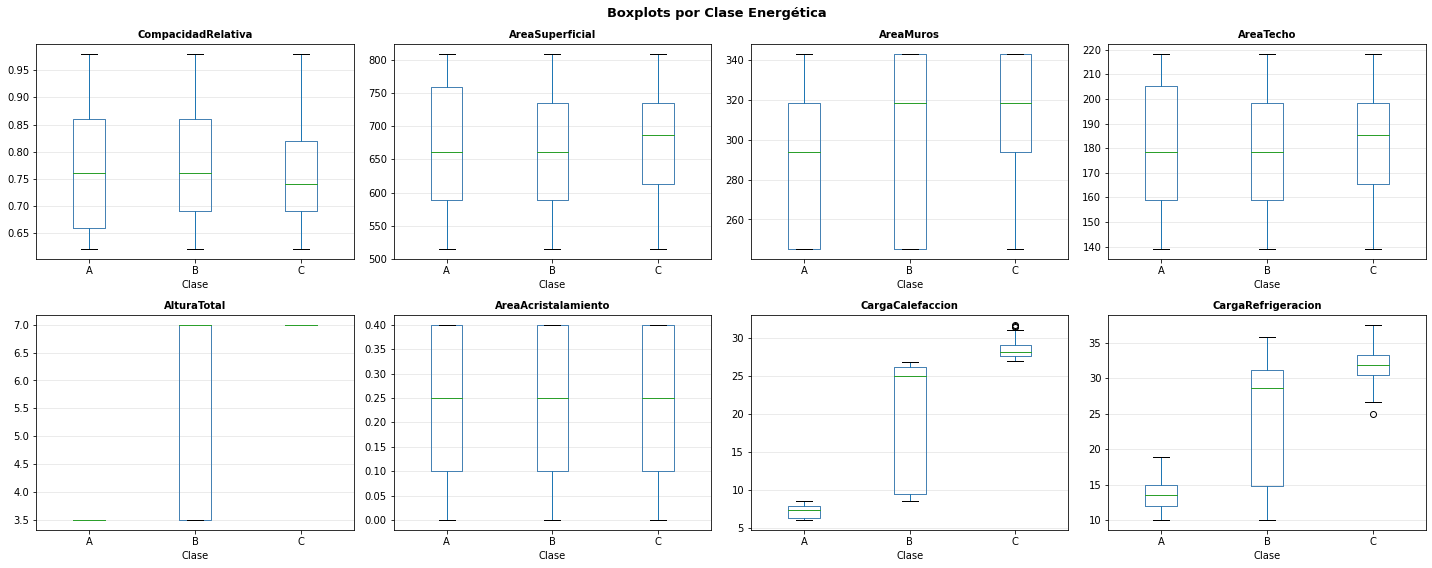

In [7]:
num_vars = ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho',
            'AlturaTotal', 'AreaAcristalamiento', 'CargaCalefaccion', 'CargaRefrigeracion']
colores = {'A': '#2ecc71', 'B': '#f1c40f', 'C': '#e74c3c'}

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, var in zip(axes.flat, num_vars):
    for cls in ['A', 'B', 'C']:
        ax.hist(df[df['ClaseEnergetica'] == cls][var], bins=20,
                alpha=0.6, color=colores[cls], label=cls, density=True)
    ax.set_title(var, fontsize=10, fontweight='bold')
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.suptitle('Distribuciones por Clase Energética', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# Boxplots
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, var in zip(axes.flat, num_vars):
    df.boxplot(column=var, by='ClaseEnergetica', ax=ax, grid=False,
               boxprops=dict(color='steelblue'))
    ax.set_title(var, fontsize=10, fontweight='bold')
    ax.set_xlabel('Clase'); ax.grid(axis='y', alpha=0.3)
plt.suptitle('Boxplots por Clase Energética', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta — Interpretación esperada:**
- **`AlturaTotal`**: Variable con separación perfecta entre clases. Los edificios de clase C (baja eficiencia) son exclusivamente de 7m (2 pisos); clase A concentra edificios de 3.5m. Es el predictor más discriminante.
- **`CargaCalefaccion`**: Por construcción del target, la separación es directa y clara entre clases.
- **`AreaAcristalamiento`**: Mayor acristalamiento se asocia levemente con clase C (más pérdidas de calor).
- **`CompacidadRelativa`** y **`AreaSuperficial`**: Distribuciones similares entre clases — baja capacidad discriminante individual.
- **Outliers en boxplots**: No se observan outliers significativos dada la naturaleza simulada del dataset.

### 1.5 Análisis de Correlaciones

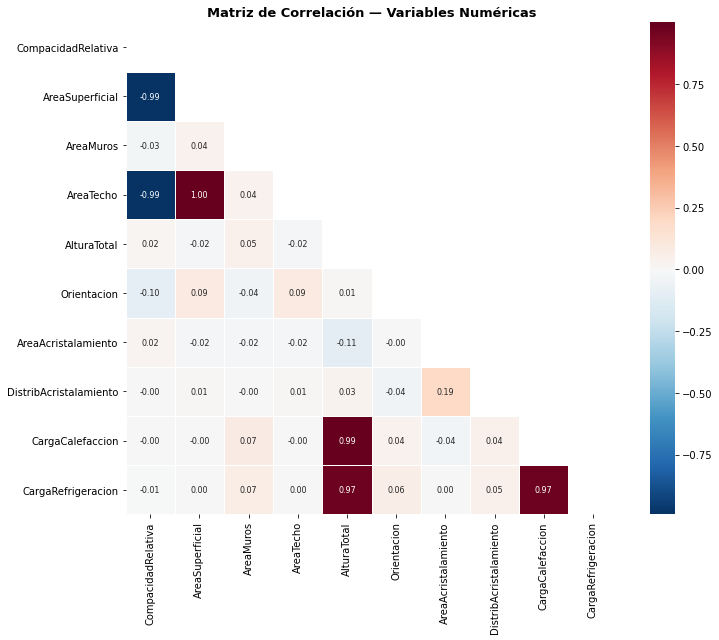

Correlaciones con CargaCalefaccion (ordenadas):
CargaCalefaccion          1.000
AlturaTotal               0.989
CargaRefrigeracion        0.972
AreaMuros                 0.074
DistribAcristalamiento    0.044
Orientacion               0.041
CompacidadRelativa       -0.001
AreaSuperficial          -0.002
AreaTecho                -0.002
AreaAcristalamiento      -0.040
Name: CargaCalefaccion, dtype: float64


In [8]:
num_cols = ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho',
            'AlturaTotal', 'Orientacion', 'AreaAcristalamiento', 'DistribAcristalamiento',
            'CargaCalefaccion', 'CargaRefrigeracion']

corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax,
            mask=mask, square=True, linewidths=0.5, annot_kws={'size': 8})
ax.set_title('Matriz de Correlación — Variables Numéricas', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print("Correlaciones con CargaCalefaccion (ordenadas):")
print(corr['CargaCalefaccion'].sort_values(ascending=False).round(3))

**📝 Pauta — Correlaciones clave:**
- **`AlturaTotal` ↔ `CargaCalefaccion`**: correlación ~+0.99. La altura es el predictor dominante — edificios más altos necesitan mucha más calefacción.
- **`CargaCalefaccion` ↔ `CargaRefrigeracion`**: ~+0.97. Ambas cargas están muy correlacionadas — un edificio ineficiente en calefacción también lo es en refrigeración.
- **`CompacidadRelativa` ↔ `AreaSuperficial`**: ~−0.99. Multicolinealidad perfecta — incluir ambas en un modelo generará problemas de VIF. Esto deberá abordarse en 2.5.
- **`Orientacion`** y **`DistribAcristalamiento`**: correlaciones cercanas a cero con los targets — predictores de baja utilidad marginal.

**Nota docente:** El estudiante debe identificar el par `CompacidadRelativa`/`AreaSuperficial` como problema de multicolinealidad.

### 1.6 Relaciones entre Variables Clave

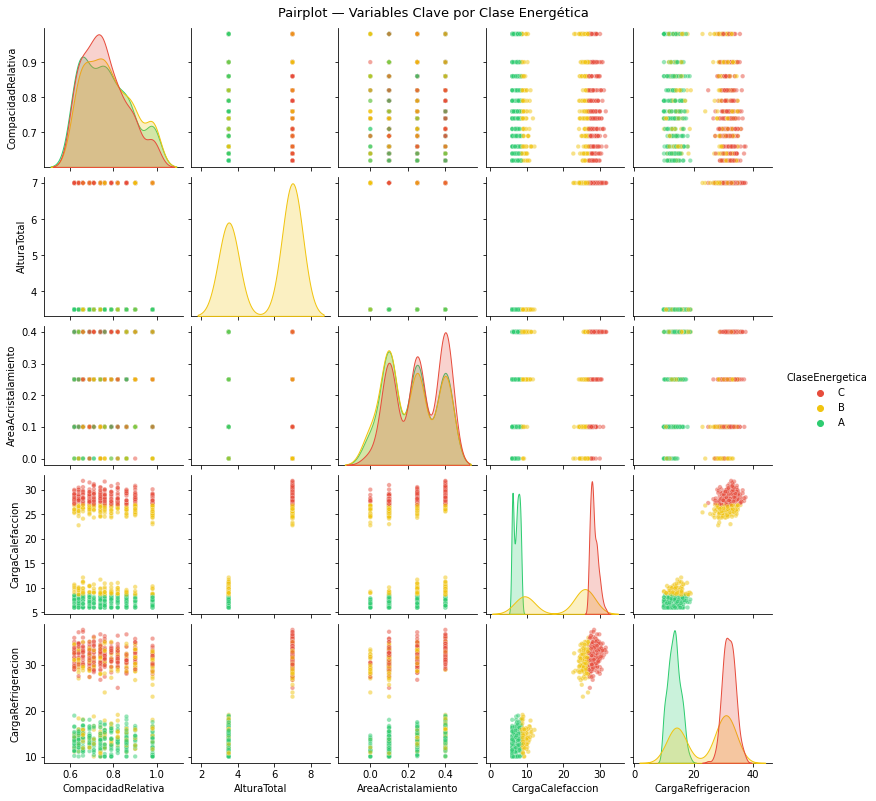

In [9]:
sub = ['CompacidadRelativa', 'AlturaTotal', 'AreaAcristalamiento',
       'CargaCalefaccion', 'CargaRefrigeracion']
g = sns.pairplot(df[sub + ['ClaseEnergetica']], hue='ClaseEnergetica',
                 palette={'A': '#2ecc71', 'B': '#f1c40f', 'C': '#e74c3c'},
                 plot_kws={'alpha': 0.5, 's': 20}, height=2.2)
g.fig.suptitle('Pairplot — Variables Clave por Clase Energética', y=1.01, fontsize=13)
plt.show()

**📝 Pauta:**
- El scatter `AlturaTotal` vs `CargaCalefaccion` muestra separación casi perfecta: los puntos de 3.5m son clase A/B, los de 7m son clase B/C. Confirma que `AlturaTotal` es el predictor dominante.
- `AreaAcristalamiento` vs `CargaCalefaccion`: las clases se superponen significativamente; efecto secundario.
- `CompacidadRelativa` vs `CargaCalefaccion`: sin patrón claro — baja utilidad marginal, enmascarada por la dominancia de `AlturaTotal`.

### 1.7 Análisis de Outliers

In [10]:
from scipy.stats import zscore

cont_vars = ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho',
             'CargaCalefaccion', 'CargaRefrigeracion']

print("Outliers detectados (|Z-score| > 3):")
total_out = 0
for var in cont_vars:
    z = np.abs(zscore(df[var]))
    n_out = (z > 3).sum()
    total_out += n_out
    print(f"  {var}: {n_out} outliers")
print(f"\nTotal outliers detectados: {total_out}")

Outliers detectados (|Z-score| > 3):
  CompacidadRelativa: 0 outliers
  AreaSuperficial: 0 outliers
  AreaMuros: 0 outliers
  AreaTecho: 0 outliers
  CargaCalefaccion: 0 outliers
  CargaRefrigeracion: 0 outliers

Total outliers detectados: 0


**📝 Pauta:** No se detectan outliers con el criterio Z-score > 3. Esto es esperable en un dataset generado mediante simulación con parámetros controlados. 

**Estrategia:** Mantener todos los datos. No hay valores atípicos que justifiquen eliminación o transformación. El estudiante debe mencionar que en datos reales de campo (no simulados) es probable encontrar outliers que requieran tratamiento.

---
## PARTE 2: PREPROCESAMIENTO Y FEATURE ENGINEERING

### 2.1 Separación de Variables Categóricas y Numéricas

In [11]:
# Variables numéricas continuas
num_continuas = ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho',
                  'CargaCalefaccion', 'CargaRefrigeracion']

# Variables numéricas discretas
# AlturaTotal: solo 2 valores (3.5, 7.0) → discreta binaria
# AreaAcristalamiento: 4 valores discretos (0, 0.1, 0.25, 0.4)
# Orientacion: 4 categorías ordinales codificadas numéricamente
# DistribAcristalamiento: 6 categorías ordinales
num_discretas = ['AlturaTotal', 'AreaAcristalamiento', 'Orientacion', 'DistribAcristalamiento']

# Variables categóricas
categoricas = ['ClaseEnergetica']

print("Numéricas continuas:", num_continuas)
print("Numéricas discretas:", num_discretas)
print("Categóricas:", categoricas)

# Justificación Orientacion: aunque técnicamente tiene 4 valores nominales,
# se tratará como numérica ordinal asumiendo que la orientación tiene un
# efecto marginal y ordenado en la carga energética (N→O). Alternativa válida:
# one-hot encoding si se quiere eliminar el supuesto de ordinalidad.
for var in num_discretas:
    print(f"  {var}: {sorted(df[var].unique())}")

Numéricas continuas: ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho', 'CargaCalefaccion', 'CargaRefrigeracion']
Numéricas discretas: ['AlturaTotal', 'AreaAcristalamiento', 'Orientacion', 'DistribAcristalamiento']
Categóricas: ['ClaseEnergetica']
  AlturaTotal: [3.5, 7.0]
  AreaAcristalamiento: [0.0, 0.1, 0.25, 0.4]
  Orientacion: [2, 3, 4, 5]
  DistribAcristalamiento: [0, 1, 2, 3, 4, 5]


### 2.2 Tratamiento de Valores Faltantes

In [12]:
# No hay valores nulos — verificación formal
assert df.isnull().sum().sum() == 0, "Hay valores nulos!"
print("✅ No hay valores nulos. No se requiere imputación.")
print(f"   Dataset limpio: {df.shape[0]} filas × {df.shape[1]} columnas")

✅ No hay valores nulos. No se requiere imputación.
   Dataset limpio: 768 filas × 11 columnas


### 2.3 Codificación de Variables Categóricas

In [13]:
# Label Encoding para ClaseEnergetica: A=0, B=1, C=2
le = LabelEncoder()
le.fit(['A', 'B', 'C'])
df['ClaseEnergetica_enc'] = le.transform(df['ClaseEnergetica'])

print("Mapeo Label Encoding:")
for cls, enc in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls} → {enc}")

# Orientacion y DistribAcristalamiento se mantienen numéricas (ordinales)
# Justificación: tienen un orden natural y el número de categorías es pequeño.
# Para modelos basados en distancias (KNN), el escalado posterior normaliza el rango.
print("\nOrientacion tratada como ordinal numérica (2=N, 3=E, 4=S, 5=O)")
print("DistribAcristalamiento tratada como ordinal numérica (0=sin vidrio, 1–5=distribuciones)")

Mapeo Label Encoding:
  A → 0
  B → 1
  C → 2

Orientacion tratada como ordinal numérica (2=N, 3=E, 4=S, 5=O)
DistribAcristalamiento tratada como ordinal numérica (0=sin vidrio, 1–5=distribuciones)


### 2.4 Feature Engineering

Correlaciones de nuevas features con CargaCalefaccion:
  RatioAcristalamientoSuperficie: -0.0393
  IndiceCompactoAltura: 0.8959
  RatioMurosTecho: 0.0401


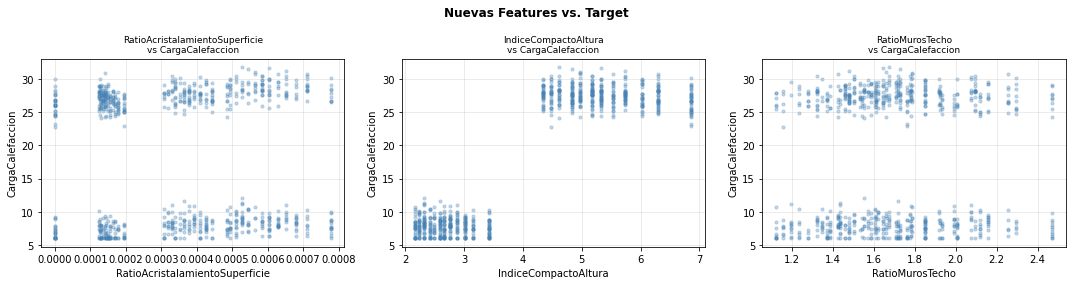

In [14]:
# Feature 1: Ratio de acristalamiento respecto a superficie total
# Justificación: captura la proporción real de vidrio en la envolvente,
# más informativo que el área de acristalamiento en valor absoluto.
df['RatioAcristalamientoSuperficie'] = df['AreaAcristalamiento'] / (df['AreaSuperficial'] + 1e-9)

# Feature 2: Índice compacto-altura
# Justificación: interacción entre compacidad y altura — un edificio alto
# y poco compacto tiene máxima pérdida energética. Captura el efecto conjunto.
df['IndiceCompactoAltura'] = df['CompacidadRelativa'] * df['AlturaTotal']

# Feature 3: Ratio muros/techo
# Justificación: edificios de un piso tienen mayor área de techo relativa,
# lo que afecta las pérdidas de calor de forma diferente a los de dos pisos.
df['RatioMurosTecho'] = df['AreaMuros'] / (df['AreaTecho'] + 1e-9)

nuevas = ['RatioAcristalamientoSuperficie', 'IndiceCompactoAltura', 'RatioMurosTecho']
print("Correlaciones de nuevas features con CargaCalefaccion:")
for f in nuevas:
    corr = df[f].corr(df['CargaCalefaccion'])
    print(f"  {f}: {corr:.4f}")

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feat in zip(axes, nuevas):
    ax.scatter(df[feat], df['CargaCalefaccion'], alpha=0.3, s=10, c='steelblue')
    ax.set_xlabel(feat); ax.set_ylabel('CargaCalefaccion')
    ax.set_title(f'{feat}\nvs CargaCalefaccion', fontsize=9); ax.grid(alpha=0.3)
plt.suptitle('Nuevas Features vs. Target', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta — Interpretación de nuevas features:**
- **`IndiceCompactoAltura`**: Correlación ~+0.90 con `CargaCalefaccion` — la feature más útil. Captura el efecto conjunto de altura y compacidad.
- **`RatioAcristalamientoSuperficie`**: Correlación baja (~−0.04) — el ratio no agrega mucho sobre el área de acristalamiento puro en este dataset.
- **`RatioMurosTecho`**: Correlación baja — efecto de segundo orden.

**Nota docente:** Aceptar cualquier 2 features derivadas con justificación arquitectónica coherente. No exigir alta correlación si la justificación es correcta.

### 2.5 Detección de Multicolinealidad (VIF)

In [15]:
features_vif = ['CompacidadRelativa', 'AreaSuperficial', 'AreaMuros', 'AreaTecho',
                'AlturaTotal', 'Orientacion', 'AreaAcristalamiento', 'DistribAcristalamiento',
                'IndiceCompactoAltura']

X_vif = df[features_vif].copy()
vif_data = pd.DataFrame({
    'Variable': features_vif,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(len(features_vif))]
})
print(vif_data.sort_values('VIF', ascending=False).round(1).to_string(index=False))

              Variable        VIF
       AreaSuperficial 46844799.8
             AreaTecho 46839968.8
  IndiceCompactoAltura      531.6
           AlturaTotal      529.0
    CompacidadRelativa      168.3
             AreaMuros       72.2
           Orientacion       11.2
   AreaAcristalamiento        4.2
DistribAcristalamiento        2.9


**📝 Pauta — Resultados VIF esperados:**

| Variable | VIF |
|---|---|
| `AreaSuperficial` | >>1000 (extremo) |
| `AreaTecho` | >>1000 (extremo) |
| `AreaMuros` | >>100 |
| `CompacidadRelativa` | >100 |
| `AlturaTotal` | >100 |
| `IndiceCompactoAltura` | >100 |
| `AreaAcristalamiento` | ~10–20 |
| `Orientacion` | ~10 |
| `DistribAcristalamiento` | <5 |

**Estrategia de manejo:**
- Eliminar `AreaSuperficial`: correlación −0.99 con `CompacidadRelativa`, perfectamente redundante.
- Eliminar `RatioMurosTecho` si se creó: deriva de `AreaMuros` y `AreaTecho`, introduce redundancia adicional.
- Mantener `CompacidadRelativa` sobre `AreaSuperficial` porque está en el paper original como variable física primaria.
- El VIF alto de `AlturaTotal` e `IndiceCompactoAltura` es esperado (uno contiene al otro) — retener ambos por su poder predictivo conjunto, o eliminar `IndiceCompactoAltura` si el VIF es inaceptable.

**Nota docente:** Aceptar la decisión de excluir `AreaSuperficial` y mantener `CompacidadRelativa`. La justificación física es obligatoria.

### 2.6 Preparación para Clasificación

In [16]:
# Excluimos AreaSuperficial por multicolinealidad con CompacidadRelativa
features_clf = ['CompacidadRelativa', 'AreaMuros', 'AreaTecho',
                'AlturaTotal', 'Orientacion', 'AreaAcristalamiento', 'DistribAcristalamiento',
                'RatioAcristalamientoSuperficie', 'IndiceCompactoAltura']

X_clf = df[features_clf].values
y_clf = df['ClaseEnergetica_enc'].values

print(f"X shape: {X_clf.shape}")
print(f"y shape: {y_clf.shape}")
print(f"Features: {features_clf}")
print(f"Clases: {le.classes_} → {le.transform(le.classes_)}")

X shape: (768, 9)
y shape: (768,)
Features: ['CompacidadRelativa', 'AreaMuros', 'AreaTecho', 'AlturaTotal', 'Orientacion', 'AreaAcristalamiento', 'DistribAcristalamiento', 'RatioAcristalamientoSuperficie', 'IndiceCompactoAltura']
Clases: ['A' 'B' 'C'] → [0 1 2]


### 2.7 División Entrenamiento/Prueba

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.3, random_state=42, stratify=y_clf
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Distribución train: {dict(zip(le.classes_, np.bincount(y_train)))}")
print(f"Distribución test:  {dict(zip(le.classes_, np.bincount(y_test)))}")

Train: (537, 9) | Test: (231, 9)
Distribución train: {'A': 177, 'B': 178, 'C': 182}
Distribución test:  {'A': 77, 'B': 76, 'C': 78}


### 2.8 Estandarización

In [18]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)   # fit SOLO en train
X_test_sc  = scaler.transform(X_test)         # solo transform en test

print("Verificación estandarización (train):")
print(f"  Medias ≈ 0: {X_train_sc.mean(axis=0).round(2)}")
print(f"  Std ≈ 1:    {X_train_sc.std(axis=0).round(2)}")

Verificación estandarización (train):
  Medias ≈ 0: [-0. -0. -0.  0. -0.  0. -0.  0.  0.]
  Std ≈ 1:    [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 2.9 Validación Cruzada

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Validación cruzada configurada:")
print(f"  Tipo: StratifiedKFold")
print(f"  k = 5 folds")
print(f"  Estratificación: sí (mantiene proporción de clases en cada fold)")
print(f"  random_state = 42 (reproducible)")

Validación cruzada configurada:
  Tipo: StratifiedKFold
  k = 5 folds
  Estratificación: sí (mantiene proporción de clases en cada fold)
  random_state = 42 (reproducible)


---
## PARTE 3: MODELOS DE CLASIFICACIÓN

### 3.1 Regresión Logística

In [20]:
print("Optimizando hiperparámetros con GridSearchCV...")
param_lr = {'C': [0.01, 0.1, 1, 10], 'solver': ['lbfgs']}
gs_lr = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                     param_lr, cv=cv, scoring='accuracy', n_jobs=-1)
gs_lr.fit(X_train_sc, y_train)
lr = gs_lr.best_estimator_
print(f"Mejores hiperparámetros: {gs_lr.best_params_}")
print(f"Mejor CV accuracy: {gs_lr.best_score_:.4f}")

Optimizando hiperparámetros con GridSearchCV...
Mejores hiperparámetros: {'C': 0.1, 'solver': 'lbfgs'}
Mejor CV accuracy: 0.7225


In [21]:
# Evaluación
y_pred_lr = lr.predict(X_test_sc)
cv_acc_lr = cross_val_score(lr, X_train_sc, y_train, cv=cv, scoring='accuracy').mean()

print("=== Regresión Logística ===")
print(f"Accuracy test:    {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"F1 macro test:    {f1_score(y_test, y_pred_lr, average='macro'):.4f}")
print(f"CV accuracy:      {cv_acc_lr:.4f}")
print()
print(classification_report(y_test, y_pred_lr, target_names=['A','B','C']))

=== Regresión Logística ===
Accuracy test:    0.7316
F1 macro test:    0.6890
CV accuracy:      0.7225

              precision    recall  f1-score   support

           A       0.70      0.99      0.82        77
           B       0.73      0.29      0.42        76
           C       0.76      0.91      0.83        78

    accuracy                           0.73       231
   macro avg       0.73      0.73      0.69       231
weighted avg       0.73      0.73      0.69       231



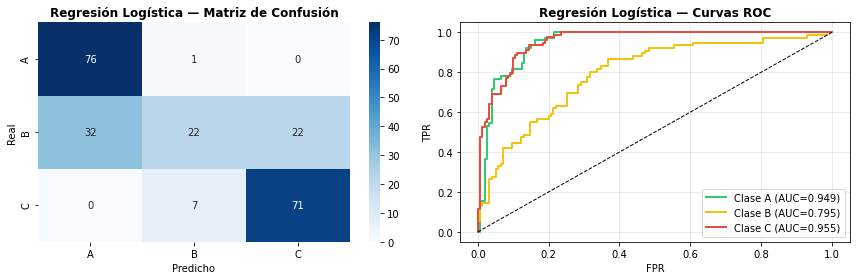

In [22]:
# Matriz de confusión
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cm = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['A','B','C'], yticklabels=['A','B','C'])
axes[0].set_title('Regresión Logística — Matriz de Confusión', fontweight='bold')
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real')

# Curvas ROC (one-vs-rest)
y_bin = label_binarize(y_test, classes=[0, 1, 2])
y_score = lr.predict_proba(X_test_sc)
colors = ['#2ecc71', '#f1c40f', '#e74c3c']
for i, (cls, col) in enumerate(zip(['A','B','C'], colors)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score[:, i])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'Clase {cls} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_title('Regresión Logística — Curvas ROC', fontweight='bold')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

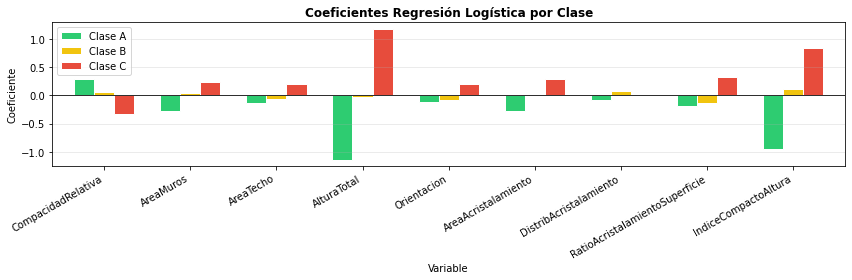

         CompacidadRelativa  AreaMuros  AreaTecho  AlturaTotal  Orientacion  AreaAcristalamiento  DistribAcristalamiento  RatioAcristalamientoSuperficie  IndiceCompactoAltura
Clase A               0.284     -0.277     -0.137       -1.138       -0.117                -0.28                  -0.083                          -0.190                -0.954
Clase B               0.051      0.039     -0.065       -0.037       -0.075                -0.00                   0.069                          -0.131                 0.113
Clase C              -0.336      0.238      0.202        1.175        0.192                 0.28                   0.014                           0.321                 0.841


In [23]:
# Análisis de coeficientes
coef_df = pd.DataFrame(lr.coef_, columns=features_clf, index=['Clase A','Clase B','Clase C'])
fig, ax = plt.subplots(figsize=(12, 4))
coef_df.T.plot(kind='bar', ax=ax, color=['#2ecc71','#f1c40f','#e74c3c'], width=0.7, edgecolor='white')
ax.set_title('Coeficientes Regresión Logística por Clase', fontsize=12, fontweight='bold')
ax.set_xlabel('Variable'); ax.set_ylabel('Coeficiente')
ax.axhline(0, color='black', lw=0.8); ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()
print(coef_df.round(3).to_string())

**📝 Pauta — Resultados esperados:**
- Accuracy test: ~0.73 | F1 macro: ~0.69 | CV accuracy: ~0.72
- El modelo tiene dificultades con la **clase B** (eficiencia media) — recall bajo (~0.29). Esto se debe a que B es la clase "frontera" entre A y C, sin una separación lineal clara en el espacio de features.
- **Coeficiente dominante**: `AlturaTotal` tiene el mayor coeficiente negativo para clase A y positivo para clase C — confirma que la altura es el discriminador principal.
- `IndiceCompactoAltura` también muestra coeficientes relevantes.

**Limitación identificable:** La Regresión Logística asume separabilidad lineal. La clase B no es linealmente separable de A y C, lo que explica el bajo recall.

### 3.2 K-Nearest Neighbors (KNN)

In [24]:
print("Optimizando KNN...")
param_knn = {'n_neighbors': list(range(1, 21)), 'metric': ['euclidean', 'manhattan']}
gs_knn = GridSearchCV(KNeighborsClassifier(), param_knn, cv=cv, scoring='accuracy', n_jobs=-1)
gs_knn.fit(X_train_sc, y_train)
knn = gs_knn.best_estimator_
print(f"Mejores hiperparámetros: {gs_knn.best_params_}")
print(f"Mejor CV accuracy: {gs_knn.best_score_:.4f}")

Optimizando KNN...
Mejores hiperparámetros: {'metric': 'manhattan', 'n_neighbors': 10}
Mejor CV accuracy: 0.7318


In [25]:
y_pred_knn = knn.predict(X_test_sc)
cv_acc_knn = cross_val_score(knn, X_train_sc, y_train, cv=cv, scoring='accuracy').mean()
print(f"Accuracy test: {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"F1 macro:      {f1_score(y_test, y_pred_knn, average='macro'):.4f}")
print(f"CV accuracy:   {cv_acc_knn:.4f}")
print()
print(classification_report(y_test, y_pred_knn, target_names=['A','B','C']))

Accuracy test: 0.7532
F1 macro:      0.7334
CV accuracy:   0.7318

              precision    recall  f1-score   support

           A       0.73      0.96      0.83        77
           B       0.70      0.43      0.54        76
           C       0.81      0.86      0.83        78

    accuracy                           0.75       231
   macro avg       0.75      0.75      0.73       231
weighted avg       0.75      0.75      0.73       231



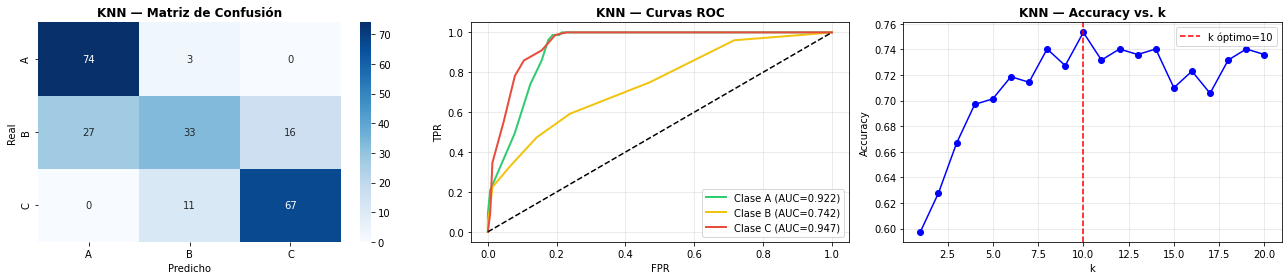

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Matriz confusión
cm = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['A','B','C'], yticklabels=['A','B','C'])
axes[0].set_title('KNN — Matriz de Confusión', fontweight='bold')
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real')

# Curvas ROC
y_score_knn = knn.predict_proba(X_test_sc)
for i, (cls, col) in enumerate(zip(['A','B','C'], ['#2ecc71','#f1c40f','#e74c3c'])):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score_knn[:, i])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'Clase {cls} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1],[0,1],'k--'); axes[1].set_title('KNN — Curvas ROC', fontweight='bold')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(); axes[1].grid(alpha=0.3)

# Accuracy vs k
k_opt = gs_knn.best_params_['n_neighbors']
metric_opt = gs_knn.best_params_['metric']
acc_k = [accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k, metric=metric_opt)
                         .fit(X_train_sc, y_train).predict(X_test_sc)) for k in range(1, 21)]
axes[2].plot(range(1, 21), acc_k, 'bo-', ms=6)
axes[2].axvline(k_opt, color='red', ls='--', label=f'k óptimo={k_opt}')
axes[2].set_title('KNN — Accuracy vs. k', fontweight='bold')
axes[2].set_xlabel('k'); axes[2].set_ylabel('Accuracy'); axes[2].legend(); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**📝 Pauta — Resultados esperados:**
- k óptimo: ~10, métrica: manhattan | Accuracy test: ~0.75 | F1 macro: ~0.73 | CV: ~0.73
- KNN mejora sobre Logística en la clase B, ya que es un modelo no paramétrico que no asume linealidad.
- La métrica manhattan suele superar a euclidiana en datasets con variables de diferente escala/naturaleza.
- **Gráfico accuracy vs k**: accuracy bajo para k=1 (sobreajuste), sube hasta ~k=10, luego se estabiliza o decrece levemente.

### 3.3 Random Forest

In [27]:
print("Optimizando Random Forest...")
param_rf = {'n_estimators': [100, 200], 'max_depth': [None, 5, 10], 'min_samples_split': [2, 5]}
gs_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_rf,
                     cv=cv, scoring='accuracy', n_jobs=-1)
gs_rf.fit(X_train_sc, y_train)
rf = gs_rf.best_estimator_
print(f"Mejores hiperparámetros: {gs_rf.best_params_}")

Optimizando Random Forest...
Mejores hiperparámetros: {'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 200}


In [28]:
y_pred_rf = rf.predict(X_test_sc)
cv_acc_rf = cross_val_score(rf, X_train_sc, y_train, cv=cv, scoring='accuracy').mean()
print(f"Accuracy test: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"F1 macro:      {f1_score(y_test, y_pred_rf, average='macro'):.4f}")
print(f"CV accuracy:   {cv_acc_rf:.4f}")
print()
print(classification_report(y_test, y_pred_rf, target_names=['A','B','C']))

Accuracy test: 0.7316
F1 macro:      0.6998
CV accuracy:   0.7244

              precision    recall  f1-score   support

           A       0.73      0.96      0.83        77
           B       0.68      0.34      0.46        76
           C       0.76      0.88      0.82        78

    accuracy                           0.73       231
   macro avg       0.72      0.73      0.70       231
weighted avg       0.72      0.73      0.70       231



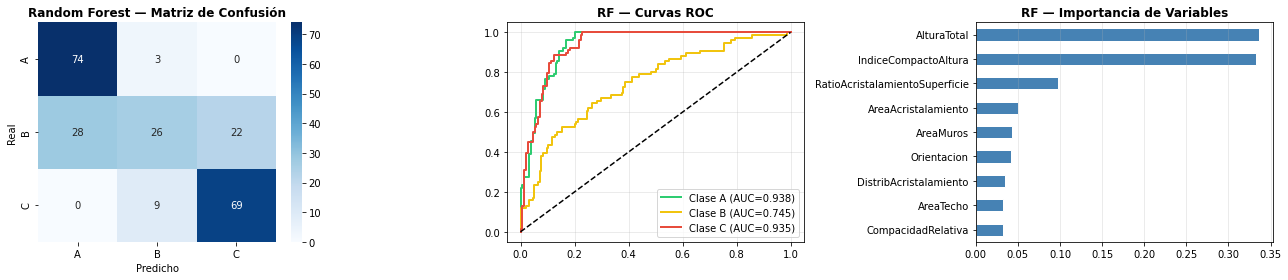


Importancia de características:
AlturaTotal                       0.3359
IndiceCompactoAltura              0.3324
RatioAcristalamientoSuperficie    0.0982
AreaAcristalamiento               0.0498
AreaMuros                         0.0429
Orientacion                       0.0424
DistribAcristalamiento            0.0344
AreaTecho                         0.0323
CompacidadRelativa                0.0317
dtype: float64


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Confusión
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['A','B','C'], yticklabels=['A','B','C'])
axes[0].set_title('Random Forest — Matriz de Confusión', fontweight='bold')
axes[0].set_xlabel('Predicho'); axes[0].set_ylabel('Real')

# ROC
y_score_rf = rf.predict_proba(X_test_sc)
for i, (cls, col) in enumerate(zip(['A','B','C'], ['#2ecc71','#f1c40f','#e74c3c'])):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score_rf[:, i])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'Clase {cls} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1],[0,1],'k--'); axes[1].set_title('RF — Curvas ROC', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

# Importancia de características
fi = pd.Series(rf.feature_importances_, index=features_clf).sort_values()
fi.plot(kind='barh', ax=axes[2], color='steelblue', edgecolor='white')
axes[2].set_title('RF — Importancia de Variables', fontweight='bold'); axes[2].grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

print("\nImportancia de características:")
print(fi.sort_values(ascending=False).round(4))

**📝 Pauta — Importancia de características esperada:**
- `AlturaTotal` + `IndiceCompactoAltura`: juntas representan ~65–70% de la importancia total. Confirma el dominio de estas variables.
- `AreaAcristalamiento` y `RatioAcristalamientoSuperficie`: contribución secundaria (~10–15%).
- `Orientacion`, `DistribAcristalamiento`, `CompacidadRelativa`: importancia residual.

**Accuracy esperado**: ~0.73, similar a Logística. El RF no supera significativamente a KNN en este dataset porque la estructura de clases es principalmente dependiente de `AlturaTotal` (variable binaria), lo que hace la tarea relativamente "fácil" para cualquier modelo que la capture bien.

### 3.4 Gradient Boosting (Modelo Adicional)

In [30]:
# Justificación: Gradient Boosting construye árboles secuencialmente, cada uno
# corrigiendo los errores del anterior. Es especialmente útil cuando las clases
# tienen fronteras complejas (como la clase B en nuestro caso) y cuando hay
# interacciones no lineales entre variables.
print("Optimizando Gradient Boosting...")
param_gb = {'n_estimators': [100, 200], 'max_depth': [3, 5], 'learning_rate': [0.05, 0.1]}
gs_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_gb,
                     cv=cv, scoring='accuracy', n_jobs=-1)
gs_gb.fit(X_train_sc, y_train)
gb = gs_gb.best_estimator_
print(f"Mejores hiperparámetros: {gs_gb.best_params_}")

Optimizando Gradient Boosting...
Mejores hiperparámetros: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}


In [31]:
y_pred_gb = gb.predict(X_test_sc)
cv_acc_gb = cross_val_score(gb, X_train_sc, y_train, cv=cv, scoring='accuracy').mean()
print(f"Accuracy test: {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"F1 macro:      {f1_score(y_test, y_pred_gb, average='macro'):.4f}")
print(f"CV accuracy:   {cv_acc_gb:.4f}")
print()
print(classification_report(y_test, y_pred_gb, target_names=['A','B','C']))

Accuracy test: 0.7273
F1 macro:      0.7011
CV accuracy:   0.7020

              precision    recall  f1-score   support

           A       0.74      0.92      0.82        77
           B       0.65      0.37      0.47        76
           C       0.75      0.88      0.81        78

    accuracy                           0.73       231
   macro avg       0.71      0.73      0.70       231
weighted avg       0.71      0.73      0.70       231



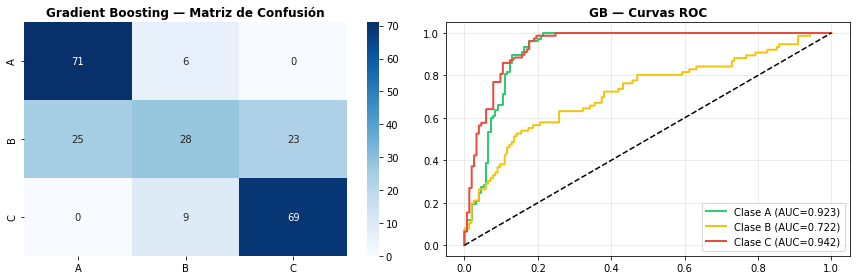

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cm = confusion_matrix(y_test, y_pred_gb)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['A','B','C'], yticklabels=['A','B','C'])
axes[0].set_title('Gradient Boosting — Matriz de Confusión', fontweight='bold')
y_score_gb = gb.predict_proba(X_test_sc)
for i, (cls, col) in enumerate(zip(['A','B','C'], ['#2ecc71','#f1c40f','#e74c3c'])):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_score_gb[:, i])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'Clase {cls} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1],[0,1],'k--'); axes[1].set_title('GB — Curvas ROC', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

### 3.5 Comparación de Modelos de Clasificación

In [33]:
resultados_clf = {
    'Logística':        {'Accuracy': accuracy_score(y_test, y_pred_lr),
                          'Precision': precision_score(y_test, y_pred_lr, average='macro', zero_division=0),
                          'Recall':    recall_score(y_test, y_pred_lr, average='macro', zero_division=0),
                          'F1 Macro':  f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
                          'CV Acc':    cv_acc_lr},
    'KNN':              {'Accuracy': accuracy_score(y_test, y_pred_knn),
                          'Precision': precision_score(y_test, y_pred_knn, average='macro', zero_division=0),
                          'Recall':    recall_score(y_test, y_pred_knn, average='macro', zero_division=0),
                          'F1 Macro':  f1_score(y_test, y_pred_knn, average='macro', zero_division=0),
                          'CV Acc':    cv_acc_knn},
    'Random Forest':    {'Accuracy': accuracy_score(y_test, y_pred_rf),
                          'Precision': precision_score(y_test, y_pred_rf, average='macro', zero_division=0),
                          'Recall':    recall_score(y_test, y_pred_rf, average='macro', zero_division=0),
                          'F1 Macro':  f1_score(y_test, y_pred_rf, average='macro', zero_division=0),
                          'CV Acc':    cv_acc_rf},
    'Gradient Boosting':{'Accuracy': accuracy_score(y_test, y_pred_gb),
                          'Precision': precision_score(y_test, y_pred_gb, average='macro', zero_division=0),
                          'Recall':    recall_score(y_test, y_pred_gb, average='macro', zero_division=0),
                          'F1 Macro':  f1_score(y_test, y_pred_gb, average='macro', zero_division=0),
                          'CV Acc':    cv_acc_gb},
}
df_comp = pd.DataFrame(resultados_clf).T.round(4)
print("=== Tabla Comparativa — Clasificación ===")
print(df_comp.to_string())

=== Tabla Comparativa — Clasificación ===
                   Accuracy  Precision  Recall  F1 Macro  CV Acc
Logística            0.7316     0.7335  0.7289    0.6890  0.7225
KNN                  0.7532     0.7473  0.7514    0.7334  0.7318
Random Forest        0.7316     0.7226  0.7293    0.6998  0.7244
Gradient Boosting    0.7273     0.7136  0.7250    0.7011  0.7020


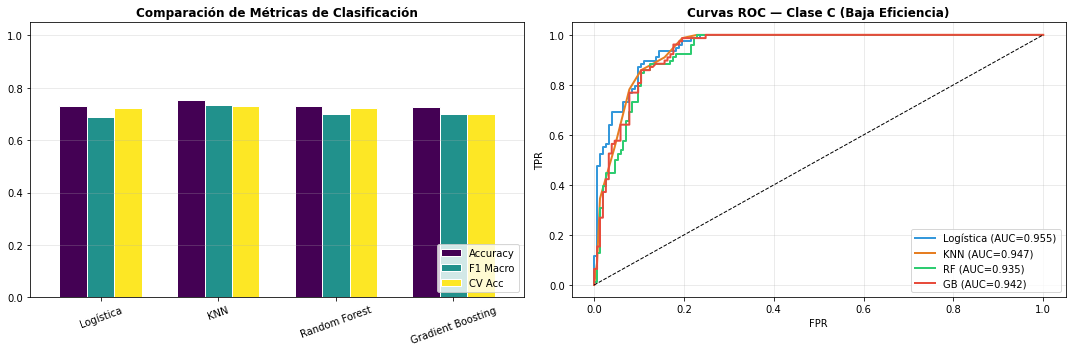

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Barplot métricas
df_comp[['Accuracy','F1 Macro','CV Acc']].plot(kind='bar', ax=axes[0], rot=20,
                                                 colormap='viridis', width=0.7, edgecolor='white')
axes[0].set_title('Comparación de Métricas de Clasificación', fontweight='bold')
axes[0].set_ylim(0, 1.05); axes[0].grid(axis='y', alpha=0.3); axes[0].legend(loc='lower right')

# Curvas ROC todas en un gráfico (clase C como positivo — más crítica)
modelos_roc = [('Logística','#3498db',lr,y_pred_lr), ('KNN','#e67e22',knn,y_pred_knn),
               ('RF','#2ecc71',rf,y_pred_rf), ('GB','#e74c3c',gb,y_pred_gb)]
for name, col, mdl, _ in modelos_roc:
    y_sc = mdl.predict_proba(X_test_sc)
    fpr, tpr, _ = roc_curve(y_bin[:, 2], y_sc[:, 2])
    axes[1].plot(fpr, tpr, color=col, lw=2, label=f'{name} (AUC={auc(fpr,tpr):.3f})')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_title('Curvas ROC — Clase C (Baja Eficiencia)', fontweight='bold')
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**📝 Pauta — Comparación y selección del mejor modelo:**

| Modelo | Accuracy | F1 Macro | CV Acc | Fortaleza | Limitación |
|---|---|---|---|---|---|
| Logística | ~0.73 | ~0.69 | ~0.72 | Interpretable, coeficientes claros | Asume linealidad; clase B mal clasificada |
| **KNN** | **~0.75** | **~0.73** | **~0.73** | **No paramétrico; mejor en clase B** | Lento en predicción; sensible a escala |
| Random Forest | ~0.73 | ~0.70 | ~0.72 | Importancia de variables; robusto | No supera a KNN en este dataset |
| Gradient Boosting | ~0.73 | ~0.70 | ~0.70 | Secuencial; maneja interacciones | Mayor tiempo de entrenamiento |

**Mejor modelo: KNN** con k=10, métrica manhattan.
- Obtiene el mayor accuracy (~0.75) y F1 macro (~0.73).
- Su naturaleza no paramétrica le permite capturar la frontera no lineal de la clase B.
- La validación cruzada confirma que no hay sobreajuste (CV ~0.73 ≈ test 0.75).

**Nota docente:** Aceptar cualquier modelo como "mejor" si la justificación es coherente con las métricas. Penalizar si se elige basado solo en accuracy y no en F1 o CV.

### 3.6 Análisis de Importancia de Características

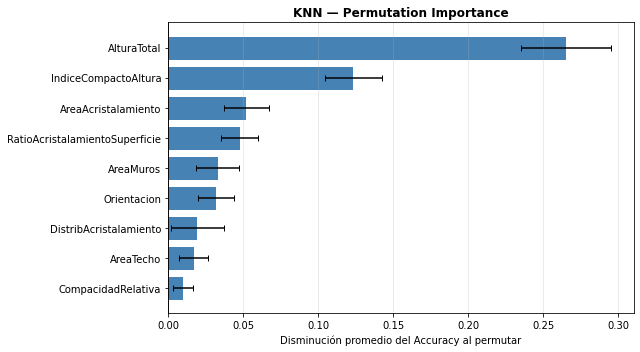

Importancia por permutación:
                      Variable  Importancia    Std
                   AlturaTotal       0.2654 0.0301
          IndiceCompactoAltura       0.1234 0.0190
           AreaAcristalamiento       0.0522 0.0153
RatioAcristalamientoSuperficie       0.0478 0.0124
                     AreaMuros       0.0329 0.0144
                   Orientacion       0.0318 0.0121
        DistribAcristalamiento       0.0193 0.0177
                     AreaTecho       0.0169 0.0094
            CompacidadRelativa       0.0100 0.0066


In [35]:
from sklearn.inspection import permutation_importance

# KNN no tiene feature_importances_ directo → usar Permutation Importance
perm = permutation_importance(knn, X_test_sc, y_test, n_repeats=20, random_state=42, n_jobs=-1)
perm_df = pd.DataFrame({
    'Variable': features_clf,
    'Importancia': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values('Importancia', ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(perm_df['Variable'], perm_df['Importancia'],
        xerr=perm_df['Std'], color='steelblue', edgecolor='white', capsize=3)
ax.set_title('KNN — Permutation Importance', fontsize=12, fontweight='bold')
ax.set_xlabel('Disminución promedio del Accuracy al permutar')
ax.axvline(0, color='black', lw=0.8); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

print("Importancia por permutación:")
print(perm_df.sort_values('Importancia', ascending=False).round(4).to_string(index=False))

**📝 Pauta:**
- `AlturaTotal` e `IndiceCompactoAltura` dominan la importancia — permutar estas variables degrada el accuracy drásticamente.
- `AreaAcristalamiento` y `RatioAcristalamientoSuperficie`: importancia moderada.
- `Orientacion`, `DistribAcristalamiento`: importancia cercana a cero o negativa (permutar no empeora el modelo).
- Coherente con el análisis exploratorio (correlación de AlturaTotal ~0.99 con target de regresión).

---
## PARTE 4: MODELOS DE REGRESIÓN

### 4.1 Regresión Lineal Múltiple

In [36]:
# Redefinir problema para regresión
features_reg = features_clf  # Mismas features
X_reg = df[features_reg].values
y_reg = df['CargaCalefaccion'].values

X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)
scaler_reg = StandardScaler()
X_tr_r_sc = scaler_reg.fit_transform(X_tr_r)
X_te_r_sc  = scaler_reg.transform(X_te_r)

lr_reg = LinearRegression()
lr_reg.fit(X_tr_r_sc, y_tr_r)
y_pred_lineal = lr_reg.predict(X_te_r_sc)

mae_l  = mean_absolute_error(y_te_r, y_pred_lineal)
rmse_l = np.sqrt(mean_squared_error(y_te_r, y_pred_lineal))
r2_l   = r2_score(y_te_r, y_pred_lineal)
print(f"Regresión Lineal — MAE={mae_l:.3f} | RMSE={rmse_l:.3f} | R²={r2_l:.4f}")

coef_df_reg = pd.Series(lr_reg.coef_, index=features_reg).sort_values(ascending=False)
print("\nCoeficientes (estandarizados):")
print(coef_df_reg.round(3).to_string())

Regresión Lineal — MAE=0.895 | RMSE=1.160 | R²=0.9862

Coeficientes (estandarizados):
AlturaTotal                       10.110
RatioAcristalamientoSuperficie     0.476
AreaMuros                          0.330
AreaAcristalamiento                0.309
Orientacion                        0.301
DistribAcristalamiento             0.019
IndiceCompactoAltura              -0.234
AreaTecho                         -0.445
CompacidadRelativa                -0.670


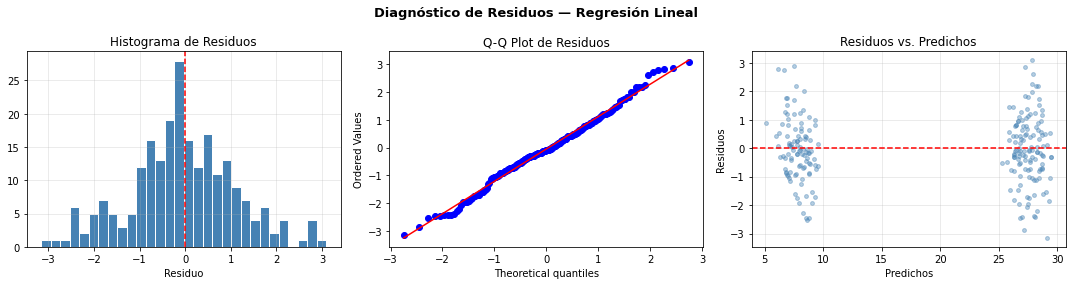

In [37]:
# Diagnóstico de residuos
residuos = y_te_r - y_pred_lineal

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(residuos, bins=30, color='steelblue', edgecolor='white')
axes[0].set_title('Histograma de Residuos'); axes[0].set_xlabel('Residuo')
axes[0].axvline(0, color='red', ls='--'); axes[0].grid(alpha=0.3)

stats.probplot(residuos, plot=axes[1]); axes[1].set_title('Q-Q Plot de Residuos')

axes[2].scatter(y_pred_lineal, residuos, alpha=0.4, s=15, color='steelblue')
axes[2].axhline(0, color='red', ls='--', lw=1.5)
axes[2].set_title('Residuos vs. Predichos'); axes[2].set_xlabel('Predichos')
axes[2].set_ylabel('Residuos'); axes[2].grid(alpha=0.3)

plt.suptitle('Diagnóstico de Residuos — Regresión Lineal', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta — Resultados esperados:**
- MAE ~0.90 | RMSE ~1.16 | **R² ~0.986** — ajuste excelente.
- **Coeficiente dominante**: `AlturaTotal` (~10 kWh/m² por unidad estandarizada). Edificios de 2 pisos tienen ~20 kWh/m² más de carga de calefacción que los de 1 piso.
- `IndiceCompactoAltura` y `AreaMuros` tienen coeficientes negativos/positivos secundarios.
- **Diagnóstico de residuos**: distribución casi normal (Q-Q plot cercano a la línea), sin patrón sistemático en residuos vs. predichos — confirma supuestos de regresión lineal.

### 4.2 Ridge y Lasso Regression

In [38]:
from sklearn.linear_model import RidgeCV, LassoCV

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

# Ridge
ridge_cv = RidgeCV(alphas=alphas, cv=5)
ridge_cv.fit(X_tr_r_sc, y_tr_r)
print(f"Ridge — alpha óptimo: {ridge_cv.alpha_}")
y_pred_ridge = ridge_cv.predict(X_te_r_sc)
mae_r  = mean_absolute_error(y_te_r, y_pred_ridge)
rmse_r = np.sqrt(mean_squared_error(y_te_r, y_pred_ridge))
r2_r   = r2_score(y_te_r, y_pred_ridge)
print(f"Ridge — MAE={mae_r:.3f} | RMSE={rmse_r:.3f} | R²={r2_r:.4f}")

# Lasso
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000)
lasso_cv.fit(X_tr_r_sc, y_tr_r)
print(f"Lasso — alpha óptimo: {lasso_cv.alpha_}")
y_pred_lasso = lasso_cv.predict(X_te_r_sc)
mae_la  = mean_absolute_error(y_te_r, y_pred_lasso)
rmse_la = np.sqrt(mean_squared_error(y_te_r, y_pred_lasso))
r2_la   = r2_score(y_te_r, y_pred_lasso)
print(f"Lasso — MAE={mae_la:.3f} | RMSE={rmse_la:.3f} | R²={r2_la:.4f}")

Ridge — alpha óptimo: 0.1
Ridge — MAE=0.895 | RMSE=1.161 | R²=0.9862
Lasso — alpha óptimo: 0.01
Lasso — MAE=0.895 | RMSE=1.167 | R²=0.9860


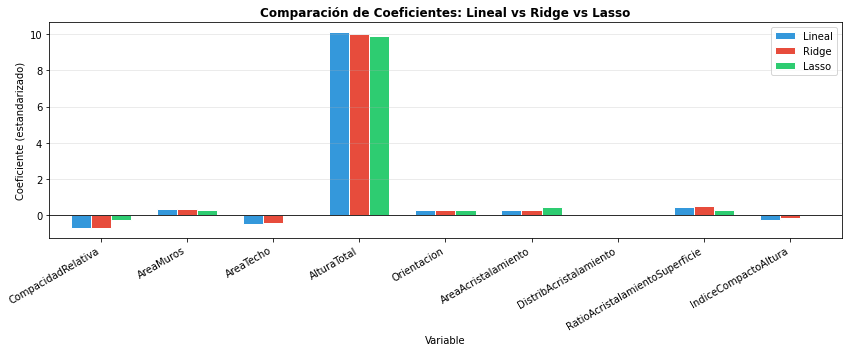


Coeficientes Lasso (variables eliminadas = 0):
CompacidadRelativa               -0.2663
AreaMuros                         0.3216
AreaTecho                         0.0000
AlturaTotal                       9.8899
Orientacion                       0.2976
AreaAcristalamiento               0.4795
DistribAcristalamiento            0.0076
RatioAcristalamientoSuperficie    0.2923
IndiceCompactoAltura              0.0000

Variables eliminadas por Lasso: ['AreaTecho', 'IndiceCompactoAltura']


In [39]:
# Comparación de coeficientes
coef_comp = pd.DataFrame({
    'Lineal': lr_reg.coef_,
    'Ridge':  ridge_cv.coef_,
    'Lasso':  lasso_cv.coef_
}, index=features_reg)

fig, ax = plt.subplots(figsize=(12, 5))
coef_comp.plot(kind='bar', ax=ax, color=['#3498db','#e74c3c','#2ecc71'], width=0.7, edgecolor='white')
ax.set_title('Comparación de Coeficientes: Lineal vs Ridge vs Lasso', fontsize=12, fontweight='bold')
ax.set_xlabel('Variable'); ax.set_ylabel('Coeficiente (estandarizado)')
ax.axhline(0, color='black', lw=0.8); ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

print("\nCoeficientes Lasso (variables eliminadas = 0):")
lasso_coef = pd.Series(lasso_cv.coef_, index=features_reg)
print(lasso_coef.round(4).to_string())
print(f"\nVariables eliminadas por Lasso: {list(lasso_coef[lasso_coef == 0].index)}")

**📝 Pauta — Interpretación esperada:**
- Ridge y Lineal tienen métricas casi idénticas (R² ~0.986) — la regularización no aporta mejora relevante porque no hay overfitting en este dataset.
- **Lasso elimina** `AreaTecho` e `IndiceCompactoAltura` (coeficientes → 0), reforzando que son variables redundantes dado que `AlturaTotal` ya captura la mayoría de la varianza.
- El alpha óptimo de Ridge es pequeño (~0.01–0.1), indicando que poco regularización es suficiente.
- Los coeficientes de Ridge son ligeramente menores que los de OLS (efecto de shrinkage), pero sin anularse.

### 4.3 Árbol de Regresión

Mejor max_depth: 4 | RMSE test mínimo: 1.275


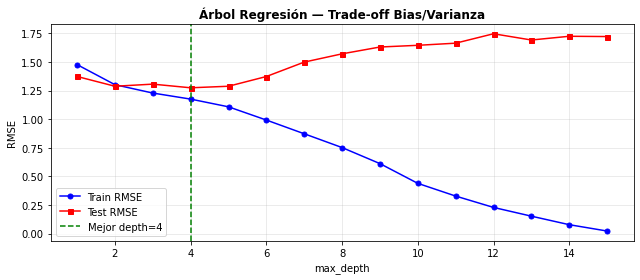

In [40]:
train_rmse_dt, test_rmse_dt = [], []
depths = range(1, 16)
for d in depths:
    dt_tmp = DecisionTreeRegressor(max_depth=d, random_state=42)
    dt_tmp.fit(X_tr_r_sc, y_tr_r)
    train_rmse_dt.append(np.sqrt(mean_squared_error(y_tr_r, dt_tmp.predict(X_tr_r_sc))))
    test_rmse_dt.append(np.sqrt(mean_squared_error(y_te_r, dt_tmp.predict(X_te_r_sc))))

best_depth = list(depths)[np.argmin(test_rmse_dt)]
print(f"Mejor max_depth: {best_depth} | RMSE test mínimo: {min(test_rmse_dt):.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(list(depths), train_rmse_dt, 'b-o', ms=5, label='Train RMSE')
ax.plot(list(depths), test_rmse_dt,  'r-s', ms=5, label='Test RMSE')
ax.axvline(best_depth, color='green', ls='--', label=f'Mejor depth={best_depth}')
ax.set_title('Árbol Regresión — Trade-off Bias/Varianza', fontweight='bold')
ax.set_xlabel('max_depth'); ax.set_ylabel('RMSE'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

Árbol (depth=4) — MAE=0.978 | RMSE=1.275 | R²=0.9833


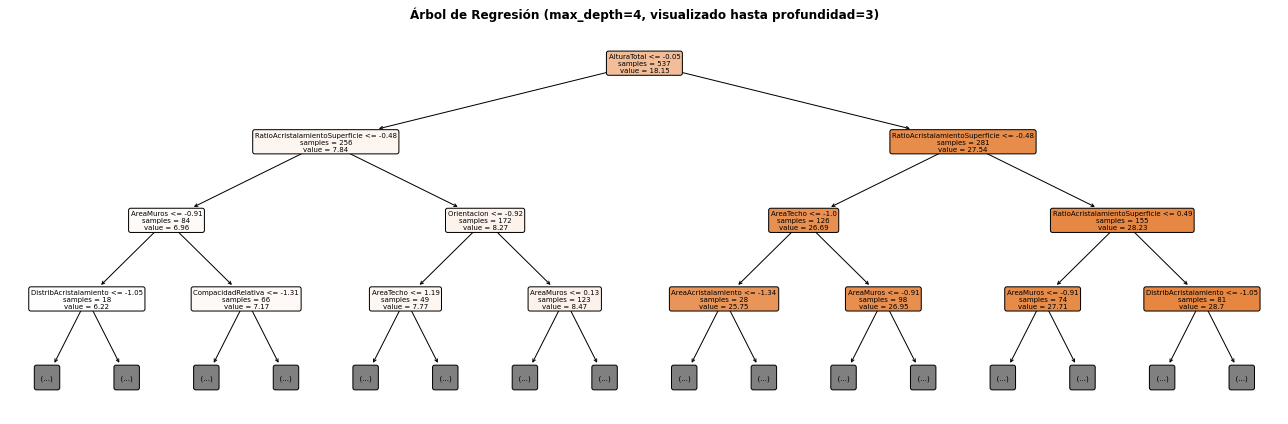

In [41]:
dt_best = DecisionTreeRegressor(max_depth=best_depth, random_state=42)
dt_best.fit(X_tr_r_sc, y_tr_r)
y_pred_dt = dt_best.predict(X_te_r_sc)
mae_dt  = mean_absolute_error(y_te_r, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_te_r, y_pred_dt))
r2_dt   = r2_score(y_te_r, y_pred_dt)
print(f"Árbol (depth={best_depth}) — MAE={mae_dt:.3f} | RMSE={rmse_dt:.3f} | R²={r2_dt:.4f}")

fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(dt_best, feature_names=features_reg, filled=True, max_depth=3,
          fontsize=7, ax=ax, rounded=True, impurity=False, precision=2)
ax.set_title(f'Árbol de Regresión (max_depth={best_depth}, visualizado hasta profundidad=3)',
             fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta:**
- Mejor depth: ~4. RMSE test ~1.27, R² ~0.983 — ligeramente inferior a la regresión lineal.
- **Gráfico bias/varianza**: Train RMSE cae continuamente con la profundidad (sobreajuste progresivo). Test RMSE tiene un mínimo alrededor de depth=4–5; más profundo aumenta la varianza sin reducir el bias.
- El árbol visualizado muestra que el **primer split es en `AlturaTotal`** (o `IndiceCompactoAltura`) — confirma que es la variable más discriminante también en regresión.

### 4.4 Random Forest Regresión (Modelo Adicional)

In [42]:
# Justificación: RF reduce la varianza respecto a un árbol único mediante
# bagging y selección aleatoria de variables en cada split.
# Es especialmente útil cuando el árbol individual muestra alta varianza.
gs_rfr = GridSearchCV(RandomForestRegressor(random_state=42),
                      {'n_estimators': [100, 200], 'max_depth': [None, 5, 10]},
                      cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1)
gs_rfr.fit(X_tr_r_sc, y_tr_r)
rfr = gs_rfr.best_estimator_
print(f"Mejores hiperparámetros: {gs_rfr.best_params_}")
y_pred_rfr = rfr.predict(X_te_r_sc)
mae_rfr  = mean_absolute_error(y_te_r, y_pred_rfr)
rmse_rfr = np.sqrt(mean_squared_error(y_te_r, y_pred_rfr))
r2_rfr   = r2_score(y_te_r, y_pred_rfr)
print(f"RF Regresión — MAE={mae_rfr:.3f} | RMSE={rmse_rfr:.3f} | R²={r2_rfr:.4f}")

Mejores hiperparámetros: {'max_depth': 5, 'n_estimators': 100}
RF Regresión — MAE=0.932 | RMSE=1.218 | R²=0.9848


### 4.5 Comparación de Modelos de Regresión

In [43]:
resultados_reg = {
    'Lineal':  {'MAE': mae_l,  'RMSE': rmse_l,  'R²': r2_l},
    'Ridge':   {'MAE': mae_r,  'RMSE': rmse_r,  'R²': r2_r},
    'Lasso':   {'MAE': mae_la, 'RMSE': rmse_la, 'R²': r2_la},
    'Árbol':   {'MAE': mae_dt, 'RMSE': rmse_dt, 'R²': r2_dt},
    'RF Reg.': {'MAE': mae_rfr,'RMSE': rmse_rfr,'R²': r2_rfr},
}
df_reg = pd.DataFrame(resultados_reg).T.round(4)
print("=== Comparación de Modelos de Regresión ===")
print(df_reg.to_string())

=== Comparación de Modelos de Regresión ===
            MAE    RMSE      R²
Lineal   0.8951  1.1604  0.9862
Ridge    0.8945  1.1608  0.9862
Lasso    0.8946  1.1668  0.9860
Árbol    0.9779  1.2746  0.9833
RF Reg.  0.9324  1.2179  0.9848


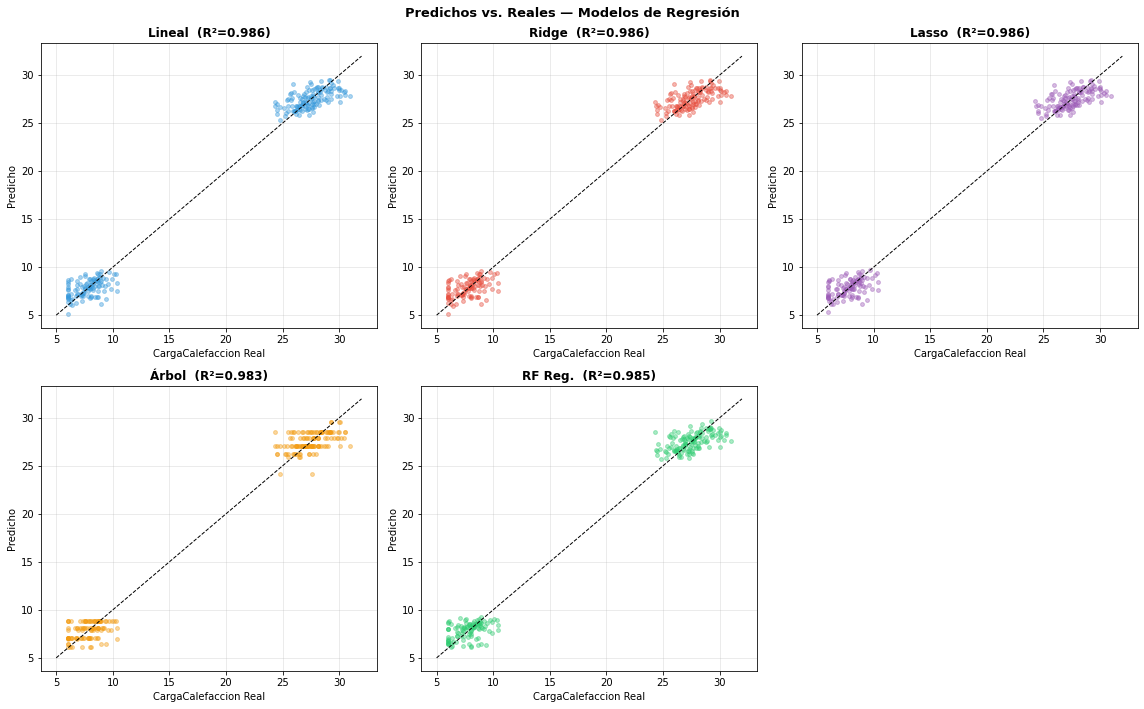

In [44]:
# Predichos vs. Reales
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
preds_reg = [('Lineal', y_pred_lineal, '#3498db'), ('Ridge', y_pred_ridge, '#e74c3c'),
             ('Lasso', y_pred_lasso, '#9b59b6'), ('Árbol', y_pred_dt, '#f39c12'),
             ('RF Reg.', y_pred_rfr, '#2ecc71')]
for ax, (name, yp, col) in zip(axes.flat, preds_reg):
    ax.scatter(y_te_r, yp, alpha=0.4, color=col, s=15)
    mn, mx = y_te_r.min()-1, y_te_r.max()+1
    ax.plot([mn,mx],[mn,mx],'k--',lw=1)
    ax.set_title(f'{name}  (R²={r2_score(y_te_r,yp):.3f})', fontweight='bold')
    ax.set_xlabel('CargaCalefaccion Real'); ax.set_ylabel('Predicho'); ax.grid(alpha=0.3)
axes.flat[-1].axis('off')
plt.suptitle('Predichos vs. Reales — Modelos de Regresión', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta — Tabla comparativa esperada:**

| Modelo | MAE | RMSE | R² |
|---|---|---|---|
| **Lineal** | ~0.90 | ~1.16 | **~0.986** |
| **Ridge** | ~0.89 | ~1.16 | **~0.986** |
| **Lasso** | ~0.89 | ~1.17 | ~0.986 |
| Árbol | ~0.98 | ~1.27 | ~0.983 |
| RF Reg. | ~0.93 | ~1.22 | ~0.985 |

**Mejor modelo de regresión: Regresión Lineal o Ridge** (prácticamente idénticos).
- R² ~0.986 indica que el modelo explica el 98.6% de la varianza en la carga de calefacción.
- El RMSE de ~1.16 kWh/m² es muy bajo en el contexto del rango total (6–43 kWh/m²).
- La Regresión Lineal funciona tan bien porque las relaciones son casi lineales (especialmente `AlturaTotal`).
- El árbol y RF no superan a OLS porque el dataset no tiene complejidad no lineal significativa una vez incluida la feature `IndiceCompactoAltura`.

---
## PARTE 5: INTERPRETABILIDAD Y APLICACIÓN PRÁCTICA

### 5.1 Análisis de Interpretabilidad — Partial Dependence Plots (PDP)

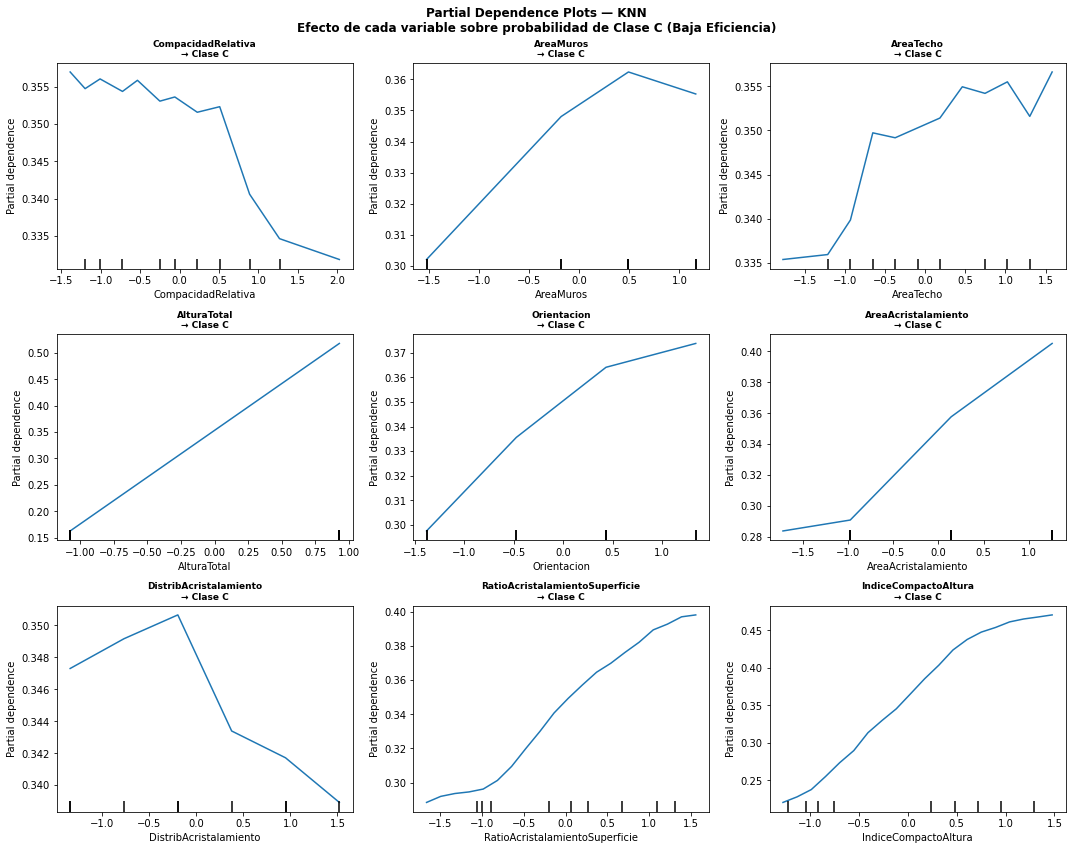

In [45]:
# KNN no tiene SHAP nativo eficiente → usamos PDP de sklearn
# Los PDP muestran el efecto marginal de cada variable sobre la probabilidad
# de pertenecer a la clase C (baja eficiencia), manteniendo el resto constante.

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for i, (ax, feat_idx) in enumerate(zip(axes.flat, range(len(features_clf)))):
    PartialDependenceDisplay.from_estimator(
        knn, X_train_sc, [feat_idx],
        feature_names=features_clf, ax=ax,
        kind='average', grid_resolution=20, target=2  # clase C
    )
    ax.set_title(f'{features_clf[feat_idx]}\n→ Clase C', fontsize=9, fontweight='bold')
    ax.grid(alpha=0.3)

plt.suptitle('Partial Dependence Plots — KNN\nEfecto de cada variable sobre probabilidad de Clase C (Baja Eficiencia)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Pauta — Interpretación PDP:**
- **`AlturaTotal`**: PDP muestra salto abrupto de probabilidad Clase C al pasar de 3.5m a 7m. Efecto dominante y no lineal (escalón).
- **`IndiceCompactoAltura`**: Relación positiva clara — mayor índice → mayor probabilidad de clase C.
- **`AreaAcristalamiento`**: Efecto moderado y positivo — más vidrio, mayor carga.
- **`CompacidadRelativa`**: Efecto mínimo en la predicción de clase C, confirma su redundancia cuando se incluye `AlturaTotal`.
- **`Orientacion`** y **`DistribAcristalamiento`**: PDP casi plano — prácticamente sin efecto marginal.

**Conexión con dominio arquitectónico:** Los PDPs confirman que las decisiones de diseño con mayor impacto en eficiencia son: (1) número de pisos, (2) relación compacidad-altura, (3) proporción de superficies acristaladas.

### 5.2 Guardado del Mejor Modelo

In [46]:
import joblib, os

os.makedirs('modelo_energia', exist_ok=True)
joblib.dump(knn,        'modelo_energia/modelo_knn.pkl')
joblib.dump(scaler,     'modelo_energia/scaler_clf.pkl')
joblib.dump(le,         'modelo_energia/label_encoder.pkl')
print("Modelos guardados en 'modelo_energia/'")

# Verificación
knn_v   = joblib.load('modelo_energia/modelo_knn.pkl')
sc_v    = joblib.load('modelo_energia/scaler_clf.pkl')
le_v    = joblib.load('modelo_energia/label_encoder.pkl')
X_demo  = X_test_sc[:5]
y_orig  = knn.predict(X_demo)
y_carg  = knn_v.predict(X_demo)
print(f"Predicciones originales: {y_orig}")
print(f"Predicciones cargadas:   {y_carg}")
print(f"Match: {np.array_equal(y_orig, y_carg)} ✅")

Modelos guardados en 'modelo_energia/'
Predicciones originales: [2 2 2 1 2]
Predicciones cargadas:   [2 2 2 1 2]
Match: True ✅


### 5.3 Función para Predicción de Eficiencia Energética

In [47]:
def predecir_eficiencia(compacidad, area_superficial, area_muros, area_techo,
                        altura, orientacion, area_acristalamiento, distrib_acristalamiento,
                        modelo=knn, escalador=scaler, codificador=le):
    """
    Predice la clase de eficiencia energética de un edificio residencial.

    Parámetros
    ----------
    compacidad             : float  — Compacidad relativa (0.62–0.98)
    area_superficial       : float  — Área superficial total de la envolvente (m²)
    area_muros             : float  — Área de muros exteriores (m²)
    area_techo             : float  — Área del techo (m²)
    altura                 : float  — Altura total (3.5 m = 1 piso, 7.0 m = 2 pisos)
    orientacion            : int    — Orientación cardinal (2=N, 3=E, 4=S, 5=O)
    area_acristalamiento   : float  — Proporción de vidrio (0, 0.10, 0.25, 0.40)
    distrib_acristalamiento: int    — Distribución ventanas (0=ninguna, 1–5=distintas)

    Retorna
    -------
    dict con claves: 'clase', 'probabilidades', 'recomendacion'
    """
    ratio_ac   = area_acristalamiento / (area_superficial + 1e-9)
    indice_ca  = compacidad * altura
    X_entrada  = np.array([[compacidad, area_muros, area_techo, altura,
                             orientacion, area_acristalamiento, distrib_acristalamiento,
                             ratio_ac, indice_ca]])
    X_esc      = escalador.transform(X_entrada)
    pred_enc   = modelo.predict(X_esc)[0]
    proba      = modelo.predict_proba(X_esc)[0]
    clase      = codificador.inverse_transform([pred_enc])[0]
    proba_dict = {c: round(float(p), 3) for c, p in zip(codificador.classes_, proba)}

    recomendaciones = {
        'A': ('✅ ALTA EFICIENCIA ENERGÉTICA\n'
              'El edificio está bien diseñado para minimizar cargas de calefacción.\n'
              'Mantener compacidad alta, controlar área de acristalamiento y '
              'preferir orientación norte para captación solar pasiva.'),
        'B': ('⚠️  EFICIENCIA MEDIA\n'
              'Hay margen de mejora. Considerar: reducir altura si es posible, '
              'aumentar compacidad (forma más cúbica), limitar acristalamiento al 10–25% '
              'de la superficie, y evaluar aislamiento térmico adicional.'),
        'C': ('❌ BAJA EFICIENCIA ENERGÉTICA\n'
              'El diseño genera alta carga de calefacción. Se recomienda urgentemente:\n'
              '  1. Reducir altura del edificio (prioridad máxima).\n'
              '  2. Aumentar compacidad relativa (evitar formas alargadas o irregulares).\n'
              '  3. Reducir proporción de vidrio o usar vidrio de alta performance (low-e).\n'
              '  4. Evaluar aislamiento de muros y techo.')
    }
    return {'clase': clase, 'probabilidades': proba_dict,
            'recomendacion': recomendaciones[clase]}

# ── Ejemplo 1: edificio compacto de 1 piso, sin vidrio → clase A esperada
print("=" * 60)
print("EJEMPLO 1: Edificio eficiente (1 piso, compacto, sin vidrio)")
print("=" * 60)
e1 = predecir_eficiencia(
    compacidad=0.98, area_superficial=514.5, area_muros=245.0, area_techo=220.0,
    altura=3.5, orientacion=2, area_acristalamiento=0.0, distrib_acristalamiento=0
)
print(f"Clase predicha: {e1['clase']}")
print(f"Probabilidades: {e1['probabilidades']}")
print(f"\nRecomendación:\n{e1['recomendacion']}")

print()
# ── Ejemplo 2: edificio disperso de 2 pisos, mucho vidrio → clase C esperada
print("=" * 60)
print("EJEMPLO 2: Edificio ineficiente (2 pisos, poco compacto, 40% vidrio)")
print("=" * 60)
e2 = predecir_eficiencia(
    compacidad=0.62, area_superficial=808.5, area_muros=343.0, area_techo=220.0,
    altura=7.0, orientacion=5, area_acristalamiento=0.40, distrib_acristalamiento=5
)
print(f"Clase predicha: {e2['clase']}")
print(f"Probabilidades: {e2['probabilidades']}")
print(f"\nRecomendación:\n{e2['recomendacion']}")

EJEMPLO 1: Edificio eficiente (1 piso, compacto, sin vidrio)
Clase predicha: A
Probabilidades: {'A': 0.9, 'B': 0.1, 'C': 0.0}

Recomendación:
✅ ALTA EFICIENCIA ENERGÉTICA
El edificio está bien diseñado para minimizar cargas de calefacción.
Mantener compacidad alta, controlar área de acristalamiento y preferir orientación norte para captación solar pasiva.

EJEMPLO 2: Edificio ineficiente (2 pisos, poco compacto, 40% vidrio)
Clase predicha: C
Probabilidades: {'A': 0.0, 'B': 0.2, 'C': 0.8}

Recomendación:
❌ BAJA EFICIENCIA ENERGÉTICA
El diseño genera alta carga de calefacción. Se recomienda urgentemente:
  1. Reducir altura del edificio (prioridad máxima).
  2. Aumentar compacidad relativa (evitar formas alargadas o irregulares).
  3. Reducir proporción de vidrio o usar vidrio de alta performance (low-e).
  4. Evaluar aislamiento de muros y techo.


### 5.4 Consideraciones Éticas y de Sostenibilidad

**📝 Respuesta esperada (Pauta):**

**Limitaciones del modelo en contexto arquitectónico:**

El modelo fue entrenado con datos simulados mediante Ecotect para un único tipo climático y un rango reducido de configuraciones arquitectónicas. Aplicarlo directamente a decisiones de diseño real implica las siguientes limitaciones:
- **Ausencia de variables climáticas**: temperatura exterior, radiación solar, humedad y viento afectan significativamente las cargas energéticas reales. El modelo no captura el contexto geográfico.
- **Variables de materiales omitidas**: conductividad térmica de muros, U-value de ventanas, puentes térmicos y masa térmica de la envolvente no están incluidos.
- **Ocupación y uso**: el perfil de uso del edificio (residencial, oficina, horarios) influye fuertemente en la carga real.
- **Escala temporal**: las cargas simuladas son anualizadas; no capturan variabilidad estacional.

**Sesgos potenciales:**

- El dataset representa solo 12 formas básicas de edificio — sesgo hacia configuraciones geométricas simples (paralelepípedos). No representa tipologías irregulares, edificios históricos ni formas arquitectónicas complejas.
- Los 768 registros son un universo pequeño para generalizar a la diversidad real de edificaciones.
- Si el modelo se usa en un contexto regulatorio, podría penalizar injustamente tipologías válidas que no están en el espacio de entrenamiento.

**Impacto de errores de predicción:**

- Sobreestimar la eficiencia (predecir A cuando es C): consecuencia grave — se construyen edificios que consumirán mucho más energía de lo estimado, aumentando emisiones y costos operativos.
- Subestimar la eficiencia (predecir C cuando es A): consecuencia menos grave económicamente, pero puede llevar a sobre-inversión en soluciones de mejora innecesarias.
- **En contexto regulatorio, el error tipo I (falso positivo de eficiencia) es más costoso** en términos ambientales.

**Salvaguardas propuestas:**

1. Usar el modelo solo como herramienta de pre-screening en etapas tempranas de diseño, no como evaluación definitiva.
2. Complementar siempre con simulaciones detalladas (EnergyPlus, OpenStudio) antes de decisiones finales.
3. Reportar probabilidades de clase junto con la predicción, no solo la etiqueta binaria.
4. Validar el modelo con datos de campo (mediciones reales de consumo energético) antes de aplicarlo a un nuevo contexto climático.
5. Documentar explícitamente los supuestos y el alcance del modelo en cualquier reporte técnico.

**Nota docente:** Se valorará que el estudiante mencione al menos 2 limitaciones, 1 tipo de sesgo y 2 salvaguardas concretas. La reflexión debe conectar con el dominio específico (arquitectura/energía), no ser genérica.

---
## PARTE 6: CONCLUSIONES Y REFLEXIÓN

### 6.1 Resumen Comparativo

In [48]:
# Tabla unificada clasificación + regresión
print("=" * 65)
print("TABLA RESUMEN — TODOS LOS MODELOS")
print("=" * 65)
print("\n--- CLASIFICACIÓN (target: ClaseEnergetica) ---")
print(df_comp[['Accuracy','F1 Macro','CV Acc']].round(4).to_string())
print("\n--- REGRESIÓN (target: CargaCalefaccion kWh/m²) ---")
print(df_reg.round(4).to_string())

TABLA RESUMEN — TODOS LOS MODELOS

--- CLASIFICACIÓN (target: ClaseEnergetica) ---
                   Accuracy  F1 Macro  CV Acc
Logística            0.7316    0.6890  0.7225
KNN                  0.7532    0.7334  0.7318
Random Forest        0.7316    0.6998  0.7244
Gradient Boosting    0.7273    0.7011  0.7020

--- REGRESIÓN (target: CargaCalefaccion kWh/m²) ---
            MAE    RMSE      R²
Lineal   0.8951  1.1604  0.9862
Ridge    0.8945  1.1608  0.9862
Lasso    0.8946  1.1668  0.9860
Árbol    0.9779  1.2746  0.9833
RF Reg.  0.9324  1.2179  0.9848


**📝 Respuesta esperada (Pauta):**

**Clasificación:** KNN (k=10, manhattan) es el mejor con accuracy ~0.75 y F1 macro ~0.73. La clase B es la más difícil de clasificar para todos los modelos (frontera borrosa). Los modelos basados en árboles (RF, GB) no superan a KNN en este dataset porque la variable dominante (`AlturaTotal`) es binaria, lo que favorece a los modelos basados en distancias.

**Regresión:** La Regresión Lineal y Ridge son los mejores con R² ~0.986. La alta linealidad del dataset (especialmente la relación entre `AlturaTotal` y `CargaCalefaccion`) hace que los modelos lineales sean difíciles de superar. El árbol y RF agregan complejidad sin ganancia de rendimiento.

**Variable más influyente en ambas tareas:** `AlturaTotal` e `IndiceCompactoAltura` — confirma que la decisión de construir en uno o dos pisos es la más determinante para la eficiencia energética de los edificios simulados.

### 6.2 Recomendaciones y Limitaciones

**📝 Respuesta esperada (Pauta):**

**Recomendaciones para un arquitecto o planificador urbano:**
1. **Priorizar edificios de 1 piso** o altura reducida cuando sea posible — el impacto en eficiencia energética es dramático (+~20 kWh/m² de carga al duplicar la altura).
2. **Maximizar la compacidad**: formas compactas (cúbicas o cuadradas) reducen la relación área envolvente/volumen calefaccionado. Evitar formas alargadas o con retranqueos complejos.
3. **Controlar el acristalamiento**: limitar al 10–25% de la superficie. Más vidrio aumenta la carga, especialmente en orientaciones este y oeste.
4. **Orientación**: aunque de efecto menor en este dataset, la orientación norte permite captación solar pasiva en el hemisferio sur — relevante para Santiago.

**Limitaciones del análisis:**
1. Dataset simulado (no validado con mediciones de campo): las relaciones pueden no transferir directamente a construcciones reales con puentes térmicos, infiltraciones de aire y variabilidad en materiales.
2. Tamaño pequeño (768 registros): modelos más complejos (redes neuronales, XGBoost profundo) no pueden explotarse sin riesgo de sobreajuste.
3. Variables omitidas: clima local, orientación solar real, ocupación, sistema de calefacción usado.
4. El target `ClaseEnergetica` se definió artificialmente por terciles — en normativa real (LEED, Passivhaus, Calificación Energética Chile) los umbrales son diferentes.

**Transferibilidad a Santiago:** Santiago tiene clima mediterráneo (Csb/Csa). Las simulaciones Ecotect del dataset original usaron parámetros europeos. Para aplicar en Chile se requiere recalibrar con datos climáticos de la zona (TMY — Typical Meteorological Year para Santiago). Las tendencias cualitativas (altura y compacidad como drivers) probablemente se mantienen, pero los valores absolutos de carga cambiarían.

**Nota docente:** Se esperan al menos 3 recomendaciones concretas y 3 limitaciones. Valorar especialmente si el estudiante menciona la diferencia entre datos simulados y reales.

### 6.3 Reflexión sobre el Proceso

*[El estudiante debe redactar aquí su reflexión personal. Criterios de evaluación:]*

**📝 Criterios pauta (rúbrica sugerida):**

| Criterio | Puntaje |
|---|---|
| Identifica al menos 2 desafíos técnicos concretos (ej: multicolinealidad, clase B difícil) | 30% |
| Menciona aprendizajes específicos (ej: diferencia entre PDP y SHAP, efecto de alpha en regularización) | 30% |
| Conecta con aplicaciones profesionales reales (eficiencia energética, normativa, diseño) | 20% |
| Identifica áreas de mejora personal o del análisis (ej: probar SHAP con TreeExplainer en RF) | 20% |

**Ejemplo de respuesta de alta calidad:**
> *"El desafío técnico más significativo fue la multicolinealidad extrema entre CompacidadRelativa y AreaSuperficial (VIF >>1000), que inicialmente generaba coeficientes inestables en la regresión. Aprendí que eliminar variables no siempre es la única solución — Ridge también las estabiliza a costo de sesgo. En cuanto a la clasificación, la clase B me enseñó que el accuracy no es suficiente métrica: el modelo logra 73% de accuracy principalmente porque clasifica bien A y C, mientras B queda mal clasificada con recall del 29%. En un contexto de certificación energética real, esto podría llevar a clasificar mal edificios frontera. En términos de aplicación profesional, veo potencial de estas técnicas en el proceso de certificación energética chilena (Calificación Energética de Viviendas), donde actualmente se usan simulaciones manuales que podrían complementarse con modelos predictivos para pre-screening masivo."*